<center><h1>Leonez, Teresa HW5</h1></center>
<br>
<br>

Name: Teresa Leonez
<br>
Github Username: ttl229
<br>
USC ID: 9630346635

## 1. Decision Trees as Interpretable Models

Import packages

In [24]:
# Import Standard Packages
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Sklearn packages
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV
from sklearn.metrics import mean_squared_error

# boost package
from xgboost import XGBRegressor, plot_importance
from xgboost import plot_tree as xgb_plot_tree

In [8]:
# Functions
# Question 1.c. Function to convert decision tree to if,then rules
def tree_to_code(tree, feature_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    print("def tree({}):".format(", ".join(feature_names)))

    def recurse(node, depth):
        indent = "    " * depth
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            print("{}if {} <= {}:".format(indent, name, threshold))
            recurse(tree_.children_left[node], depth + 1)
            print("{}else:  # if {} > {}".format(indent, name, threshold))
            recurse(tree_.children_right[node], depth + 1)
        else:
            print("{}return {}".format(indent, tree_.value[node].tolist()))

    recurse(0, 1)

# For Question 1.d. Function to cross validate and prune through alphas
def trees_by_alpha(X, y, alphas):
    results = []
    for a in alphas:
        t = DecisionTreeClassifier(criterion='entropy', ccp_alpha=a, random_state=42)
        t.fit(X,y)
        results.append({'alpha': a, 'leaves':t.get_n_leaves(), 'depth': t.get_depth(), 'train_accuracy':t.score(X,y), 'cv_acc': cross_val_score(t,X,y,cv=5).mean()
                       })
    return pd.DataFrame(results)

def get_coeff(feature_col)-> float: 
    s, m = feature_col.std(), feature_col.mean()
    cv = s/m
    return cv

def plot_box_scatter(df, target, title1:str, title2:str):
    df.boxplot(figsize=(14, 5), rot=45)       # Box plot
    print(title1)
    plt.show()
    fig, axes = plt.subplots(3, 4, figsize=(14, 9))   # Scatterplot
    for ax, col in zip(axes.flat, df.columns):
        ax.scatter(df[col], target, s=5, alpha=0.5)  # Plot each feature vs target
        ax.set_title(col, fontsize=9)
    axes.flat[-1].axis('off')   # 12 slots, 11 plots
    fig.supxlabel("Feature value")
    fig.supylabel("ViolentCrimesPerPop")
    plt.tight_layout()
    print(title2)
    plt.show()

### (a) Obtain Data

Get the Accute Inamations Data Set

In [9]:
# import data set
df = pd.read_csv('data/diagnosis.csv', sep='\t', encoding='utf-16', header=None, decimal=',')
df.columns = ['temp', 'nausea', 'lumbar_pain', 'urine_pushing',
              'micturition_pains', 'burning_urethra',
              'decision_inflammation_bladder', 'decision_nephritis_pelvis']

# Convert the responses into binary variables
df = df.replace({'yes': 1, 'no': 0})

df.head()

,temp,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,decision_inflammation_bladder,decision_nephritis_pelvis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

In [10]:
# Split independent and dependent variables
X = df.iloc[:, :6].astype(float)  # use first 6 columns as attributes/independent variables 
y = df.iloc[:, 6:].astype(int)  # use last 2 columns as dependent/multi-class prediction

Class key:
 '00' = No Inflammation, No Nephritis
'10' = Inflammation without Nephritis
'01' = No Inflammation, Yes Nephritis 
'11' = Inflammation and Nephritis



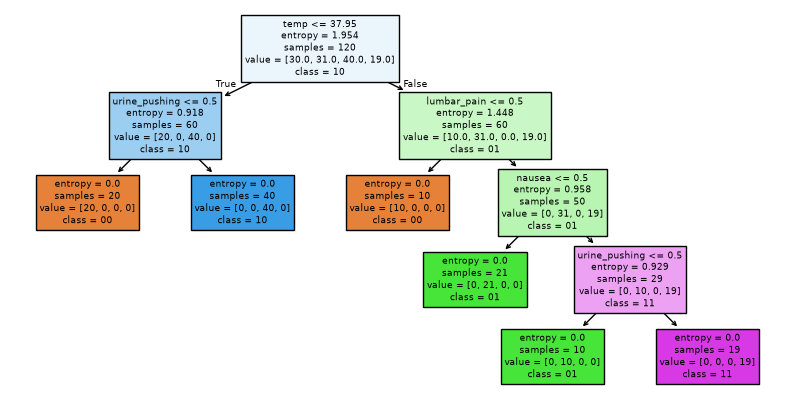

In [11]:
# Label Powerset Approach
lp_key = "Class key:\n '00' = No Inflammation, No Nephritis\n'10' = Inflammation without Nephritis\n'01' = No Inflammation, Yes Nephritis \n'11' = Inflammation and Nephritis\n"

# Combine two decision labels into 1 label with 4 classes '00', '01', '10', '11'
y_lp = y.iloc[:, -2].astype(str) + y.iloc[:, -1].astype(str)

# Fit tree to all data
lp_tree = DecisionTreeClassifier(criterion='entropy', random_state=42)
lp_tree.fit(X, y_lp)

# Plot tree
print(lp_key)
plt.figure(figsize=(10, 5))
plot_tree(lp_tree, feature_names=X.columns, class_names=lp_tree.classes_, filled=True)
plt.show()

### (c) Convert the decision rules

In [12]:
feature_names = list(X.columns)  # Set feature names as list
tree_to_code(lp_tree, feature_names) # Convert decision rules to IF-THEN rules

def tree(temp, nausea, lumbar_pain, urine_pushing, micturition_pains, burning_urethra):
    if temp <= 37.95000076293945:
        if urine_pushing <= 0.5:
            return [[1.0, 0.0, 0.0, 0.0]]
        else:  # if urine_pushing > 0.5
            return [[0.0, 0.0, 1.0, 0.0]]
    else:  # if temp > 37.95000076293945
        if lumbar_pain <= 0.5:
            return [[1.0, 0.0, 0.0, 0.0]]
        else:  # if lumbar_pain > 0.5
            if nausea <= 0.5:
                return [[0.0, 1.0, 0.0, 0.0]]
            else:  # if nausea > 0.5
                if urine_pushing <= 0.5:
                    return [[0.0, 1.0, 0.0, 0.0]]
                else:  # if urine_pushing > 0.5
                    return [[0.0, 0.0, 0.0, 1.0]]


[0.         0.19959209 0.32501121 0.45914792 0.77042604]
      alpha  leaves  depth  train_accuracy    cv_acc
0  0.000000       6      4        1.000000  0.966667
1  0.199592       4      2        0.841667  0.816667
2  0.325011       3      2        0.758333  0.725000
3  0.459148       2      1        0.591667  0.575000
4  0.770426       1      0        0.333333  0.433333


[Text(0.5, 0.8333333333333334, 'temp <= 37.95\nentropy = 1.954\nsamples = 120\nvalue = [30.0, 31.0, 40.0, 19.0]\nclass = 10'),
 Text(0.25, 0.5, 'urine_pushing <= 0.5\nentropy = 0.918\nsamples = 60\nvalue = [20, 0, 40, 0]\nclass = 10'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'entropy = 0.0\nsamples = 20\nvalue = [20, 0, 0, 0]\nclass = 00'),
 Text(0.375, 0.16666666666666666, 'entropy = 0.0\nsamples = 40\nvalue = [0, 0, 40, 0]\nclass = 10'),
 Text(0.75, 0.5, 'lumbar_pain <= 0.5\nentropy = 1.448\nsamples = 60\nvalue = [10.0, 31.0, 0.0, 19.0]\nclass = 01'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'entropy = 0.0\nsamples = 10\nvalue = [10, 0, 0, 0]\nclass = 00'),
 Text(0.875, 0.16666666666666666, 'entropy = 0.958\nsamples = 50\nvalue = [0, 31, 0, 19]\nclass = 01')]

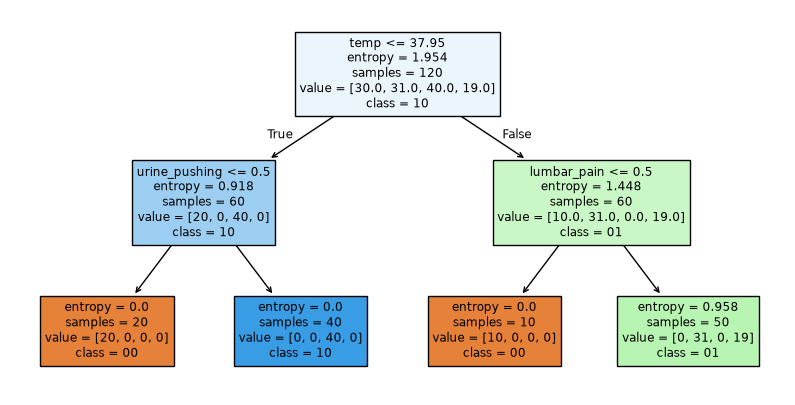

In [13]:
# Get pruning path
path = lp_tree.cost_complexity_pruning_path(X, y_lp)
ccp_alphas = path.ccp_alphas
print(ccp_alphas)

# Build tree for each alpha
pruning_df = trees_by_alpha(X, y_lp, ccp_alphas)
print(pruning_df)

# Select best alpha from results
best_alpha = pruning_df.loc[pruning_df['alpha'] > 0.199, 'alpha'].iloc[0]

# Refit model with best alpha
minimal_tree = DecisionTreeClassifier(criterion='entropy', ccp_alpha=best_alpha, random_state=42)
minimal_tree.fit(X, y_lp)

# Plot minimal decision tree
plt.figure(figsize=(10, 5))
plot_tree(minimal_tree, feature_names=list(X.columns), class_names=minimal_tree.classes_, filled=True)

The minimal decision tree was selected with alpha = .1996, resulting in 4 leaves and a training accuracy of .842 and cross validation score of .817.
The decision rules are: 
If the patient has a temperature less than or equal to 37.95 and reports urine pushing, they are predicted to have bladder inflammation only.
If the patient has a temperature less than or equal to 37.95 and does not report urine pushing, they are predicted to have neither condition.
If he patient has a temperature above 37.95 and does not report lumbar pain, they are also predicted to have neither condition.
If the patient's temperature is over 37.95, and report lumbar pain, they are predicted to have nephritis only. However, this class has an entropy of 0.958 resulting in 19 misclassifed instances in the training set that also have inflammation)

In [14]:
tree_to_code(minimal_tree, list(X.columns))

def tree(temp, nausea, lumbar_pain, urine_pushing, micturition_pains, burning_urethra):
    if temp <= 37.95000076293945:
        if urine_pushing <= 0.5:
            return [[1.0, 0.0, 0.0, 0.0]]
        else:  # if urine_pushing > 0.5
            return [[0.0, 0.0, 1.0, 0.0]]
    else:  # if temp > 37.95000076293945
        if lumbar_pain <= 0.5:
            return [[1.0, 0.0, 0.0, 0.0]]
        else:  # if lumbar_pain > 0.5
            return [[0.0, 0.62, 0.0, 0.38]]


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [15]:
# Load data
df = pd.read_csv('data/communities.data', header=None, na_values='?')

# pull feature names from communities file 
names = []   
with open('data/communities.names') as f:
    for line in f:
        if line.startswith('@attribute'):
            names.append(line.split()[1])

df.columns = names

### (b) Missing values

In [16]:
# Drop non-descriptive feature columns
crime_df = df.iloc[:, 5:].copy()

# Resplit into test and train
train_data = crime_df.iloc[:1495]
test_data = crime_df.iloc[1495:]

In [17]:
# Impute missing data
imputer = SimpleImputer(strategy='median')  # Use median imputation 
train_imp = pd.DataFrame(imputer.fit_transform(train_data), columns=train_data.columns)
test_imp  = pd.DataFrame(imputer.transform(test_data), columns=test_data.columns)

### (c) Plot a correlation matrix

<Axes: >

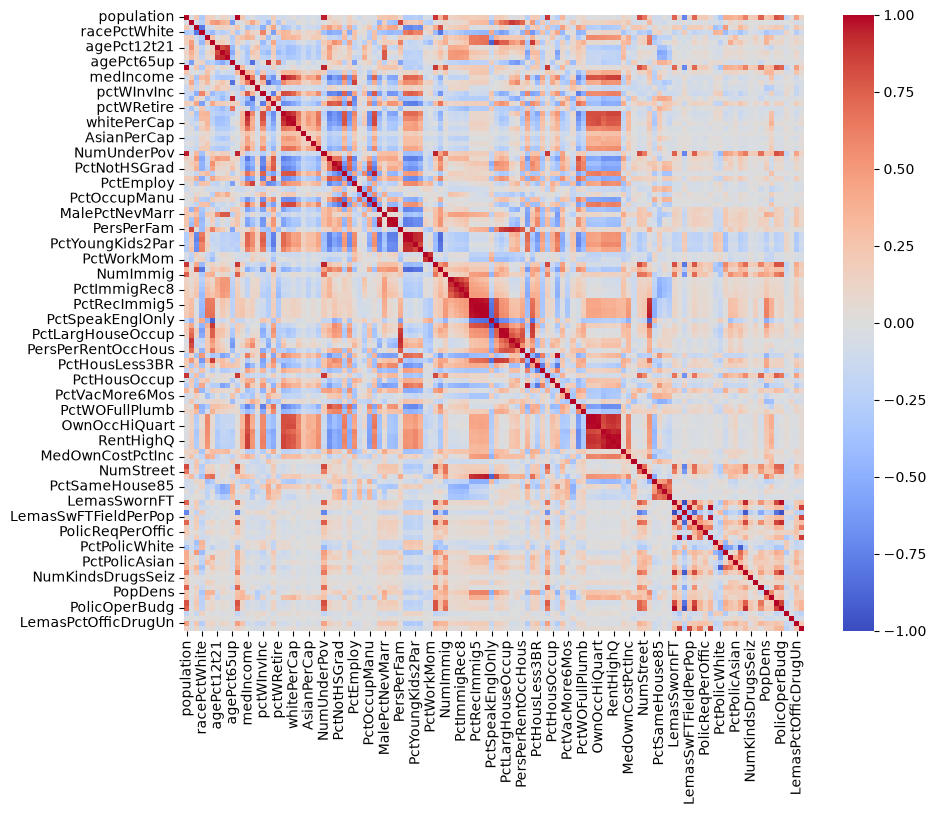

In [18]:
features = train_imp.iloc[:, :-1].copy()  # Use just the predictive features, exclude target column
corr_matrix = features.corr() # Assign to correlation matrix
plt.figure(figsize=(10,8)) # Set plot size
sns.heatmap(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1) # Plot matrix

### (d) Calculate the Coefficient of Variation CV

In [19]:
cv = features.apply(get_coeff) # get coefficient of each feature column
sorted_cv = cv.sort_values(ascending=False) # sort from highest to lowest value

# Print coefficients in table of 4 x 31 for space efficiency 
items = [f"{k[:20]:<20} {v:6.3f}" for k, v in sorted_cv.items()]
for i in range(0, len(items), 4):
    print("   ".join(items[i:i+4]))

PctPolicAsian         5.527   NumStreet             4.293   NumInShelters         3.471   NumIlleg              3.059
NumImmig              2.927   LemasPctOfficDrugUn   2.553   NumUnderPov           2.342   LemasSwornFT          2.248
population            2.241   numbUrban             2.038   HousVacant            1.968   PolicOperBudg         1.646
LandArea              1.645   racePctHisp           1.612   PctNotSpeakEnglWell   1.457   LemasTotalReq         1.452
racepctblack          1.429   PctUsePubTrans        1.397   racePctAsian          1.359   PctPolicHisp          1.354
PctRecentImmig        1.288   PctRecImmig5          1.286   PctRecImmig10         1.270   PctRecImmig8          1.266
OfficAssgnDrugUnits   1.175   PctPersDenseHous      1.133   PolicCars             1.113   PctForeignBorn        1.066
PctVacantBoarded      1.055   PctHousNoPhone        0.923   PctIlleg              0.922   OwnOccMedVal          0.889
OwnOccHiQuart         0.884   PopDens               0.86

### (e) Scatter plots and box plots for highest CV features

In [20]:
n = int(math.sqrt(128))  # calculate √128 as n
print(sorted_cv.head(n))  # Show top n features with highest CV
top_attributes = features[sorted_cv.index[:n]]  # gets data for top feature rows

PctPolicAsian          5.527059
NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
LemasSwornFT           2.248042
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
dtype: float64


Box Plot visualization of Top 11 CV Features


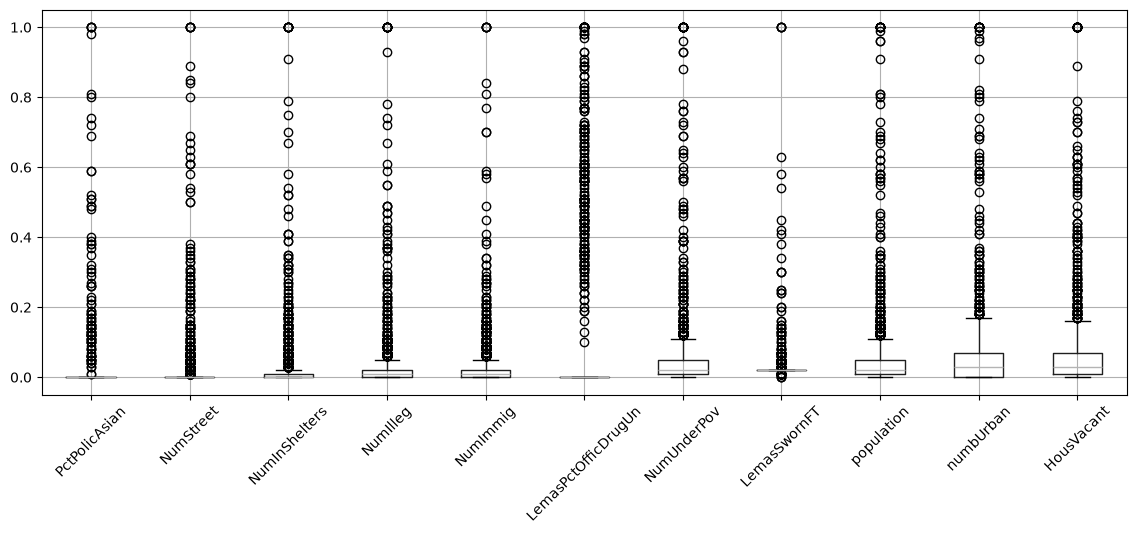

Scatter plot visualization of Top 11 CV features vs Target


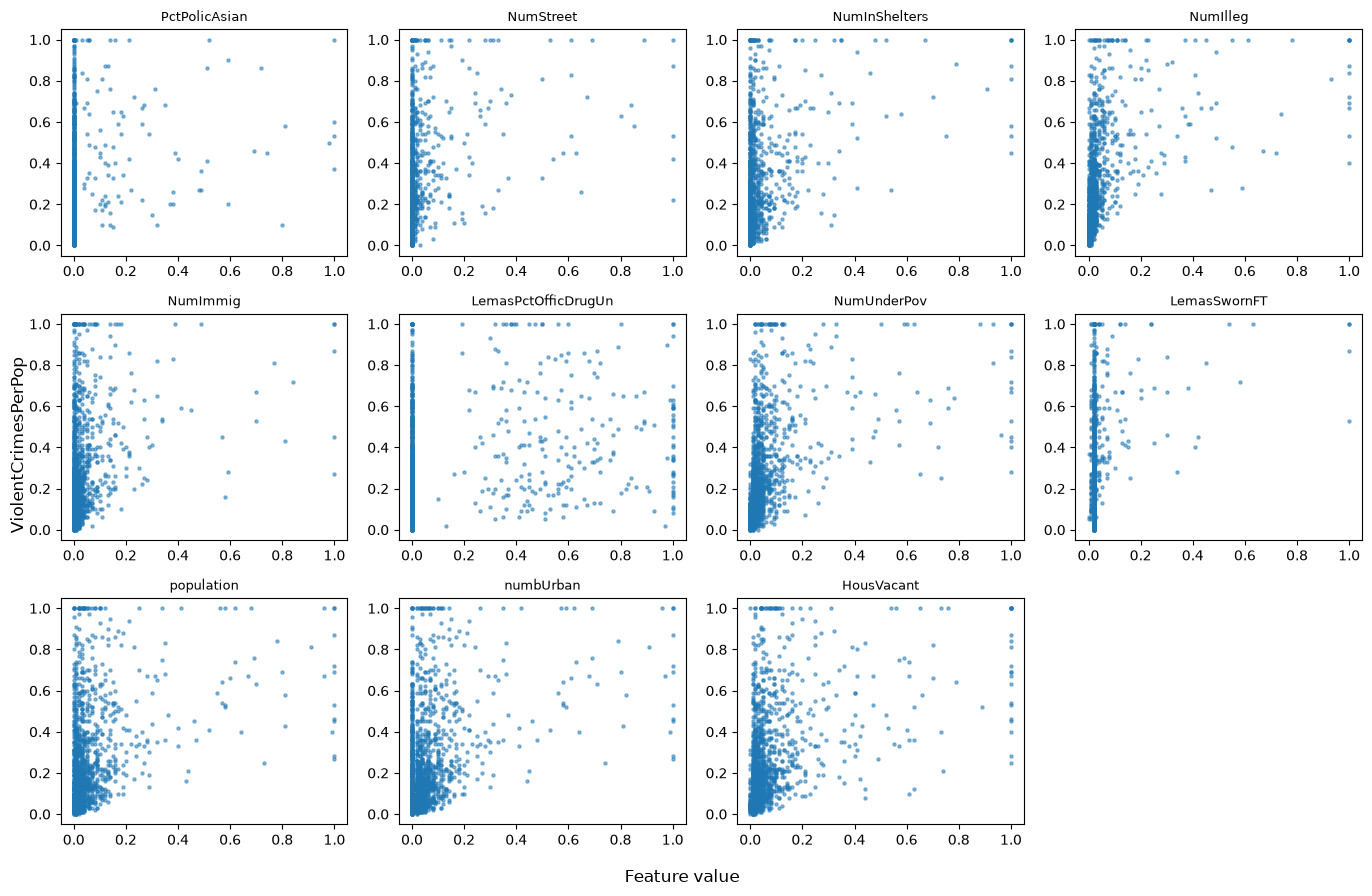

In [21]:
box_title = "Box Plot visualization of Top 11 CV Features"
scatter_title = "Scatter plot visualization of Top 11 CV features vs Target"
plot_box_scatter(top_attributes, train_imp['ViolentCrimesPerPop'], box_title, scatter_title)

We cannot draw conclusions directly about the significance of these features on the target variable from these 11 scatterplots. Almost all the features show heavy clustering of instances of low and high crime rates towards the left side of x-axis, regardless of the feature. Since these features are count variables, a few largely populated cities will skew to the right, while most cities remain clustered to the left. Since the scatter plot only shows relationship between one feature and the target at once, it does not account for other predictors interacting with each other.
with the exception of % of officers assigned to drug units (LemasPctofficDrugUn), which shows clustering on both left and right side of the x-axis representing both high and low violent crime.

### (f) Fit a linear model

In [22]:
# Pull features and target from df for linear model
X_train = train_imp.drop(columns='ViolentCrimesPerPop')
y_train = train_imp.iloc[:, -1]
X_test = test_imp.drop(columns='ViolentCrimesPerPop')
y_test = test_imp.iloc[:, -1]

# Fit the model
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
model_mse = mean_squared_error(y_test, y_pred)
print(f"Linear Regression Test MSE: {model_mse:.4f}")

Linear Regression Test MSE: 0.0180


### (g) Fit a ridge regression model

In [25]:
# Ridge Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

alphas = np.logspace(-4, 4, 100)  # CV Alphas
ridge_model = RidgeCV(alphas=alphas, cv=5)
ridge_model.fit(X_train_scaled, y_train)
ridge_mse = mean_squared_error(y_test, ridge_model.predict(X_test_scaled))

# Print results
print("Best alpha:", ridge_model.alpha_)
print(f"Ridge test MSE: {ridge_mse:.4f}")

Best alpha: 79.24828983539186
Ridge test MSE: 0.0174


### (h) Fit a LASSO model

In [26]:
# Lasso Model CV
lasso_model = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_model.fit(X_train, y_train) # Fit to non-scaled data first
lasso_mse = mean_squared_error(y_test, lasso_model.predict(X_test))
selected_lasso = X_train.columns[lasso_model.coef_ != 0]

print(f"{len(selected_lasso)} features selected:")
print(", ".join(selected_lasso))

# Rerun Lasso CV with standardized data
stand_lasso = LassoCV(cv=5, random_state=42, max_iter=10000)
stand_lasso.fit(X_train_scaled, y_train)
stand_lasso_mse = mean_squared_error(y_test, stand_lasso.predict(X_test_scaled))
selected_standard = X_train.columns[stand_lasso.coef_ != 0]

print(f"{len(selected_standard)} features selected (standardized):")
print(", ".join(selected_standard))

# Print results
print("Best alpha:", lasso_model.alpha_)
print(f"Lasso test MSE (non-scaled data): {lasso_mse:.4f}")
print("Best alpha:", stand_lasso.alpha_)
print(f"Lasso (standardized) test MSE: {stand_lasso_mse:.4f}")

# See which features were not in both sets
print("Only in non-standardized:", set(selected_lasso) - set(selected_standard))
print("Only in standardized:", set(selected_standard) - set(selected_lasso))

74 features selected:
racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameCity85, LemasSwFTFieldPerPop, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlack, PctPolicHisp, PctPolicAsian, NumKindsDrugs

The test error in the standardized lasso was slightly lower than the non-standardized test, though only by .0001. In the standardized lasso test, 50 features were dropped with 72 features selected, compared to 48 features dropped with 74 features selected in the non-standardized version. 

### (i) Fit a PCR model

In [27]:
pcr = make_pipeline(StandardScaler(), PCA(), LinearRegression())

param_grid = {'pca__n_components': range(1, X_train.shape[1] + 1)}
pcr_cv = GridSearchCV(pcr, param_grid, cv=5, scoring='neg_mean_squared_error')
pcr_cv.fit(X_train, y_train)

best_M = pcr_cv.best_params_['pca__n_components']
pcr_mse = mean_squared_error(y_test, pcr_cv.predict(X_test))
print("Best M:", best_M)
print(f"PCR test MSE: {pcr_mse:.4f}")

Best M: 95
PCR test MSE: 0.0183


### (j) Fit a boosting tree

In [28]:
xgboost = XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42)

param_grid = {'reg_alpha': np.logspace(-4, 1, 20)}
xgboost_cv = GridSearchCV(xgboost, param_grid, cv=5, scoring='neg_mean_squared_error')
xgboost_cv.fit(X_train, y_train)

best_alpha = xgboost_cv.best_params_['reg_alpha']
xgboost_mse = mean_squared_error(y_test, xgboost_cv.predict(X_test))
print("Best alpha:", best_alpha)
print(f"XGBoost test MSE: {xgboost_mse:.4f}")

Best alpha: 0.26366508987303583
XGBoost test MSE: 0.0167


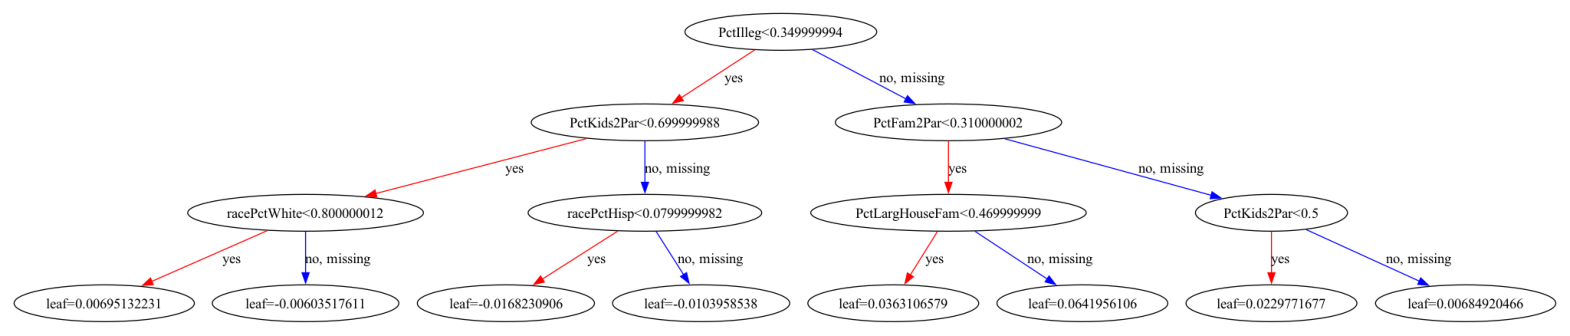

In [29]:
fig, ax = plt.subplots(figsize=(20, 10))
xgb_plot_tree(xgboost_cv.best_estimator_, tree_idx=0, ax=ax)   # Show first tree
plt.show()

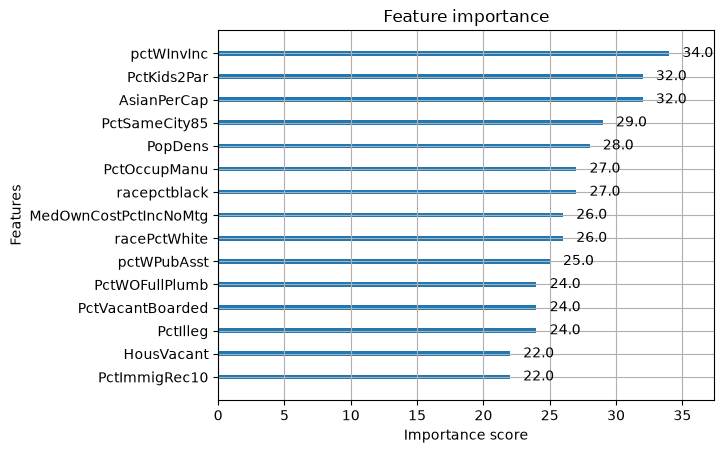

In [31]:
# Show most important features
plot_importance(xgboost_cv.best_estimator_, max_num_features=15)
plt.show()

Using XGBoost to fit a L-1 penalized gradient boosting tree, the best regularization alpha is 0.26367 through cross-validation, with test error of 0.0167. This test error is lower than the lasso and ridge model. One possible reason is that boosted trees can capture non-linear relationships and feature interactions while linear models such as Lasso, Ridge, and PCR cannot.